# Mortgage credit risk at Canada's Big Six banks, 2018–2026
### A PACE analysis of OSFI's E3 and M4 regulatory returns

**Author:** Jeelay Pillai &nbsp;·&nbsp; **Data to:** Q2 2026 (quarter ending April 2026) for E3, July 2026 for M4 &nbsp;·&nbsp; **Tools:** PostgreSQL 16, Python (pandas, statsmodels, matplotlib), Power BI, Tableau

## 1. Description and deliverables

This project measures how mortgage credit risk at Canada's six largest banks (RBC, TD, Scotiabank (BNS), BMO, CIBC and National Bank (NBC)) moved through the 2022–2024 interest-rate cycle. It uses the returns the banks file with their regulator, the Office of the Superintendent of Financial Institutions (OSFI).

| Deliverable | Where |
|---|---|
| This notebook, following the PACE stages (Plan, Analyze, Construct, Execute) | `notebooks/` |
| PostgreSQL warehouse: raw files → star schema → analysis marts, with automated data-quality checks | `sql/`, `src/build_database.py` |
| Power BI report (Power BI Project: TMDL semantic model, DAX measures, report pages) | `powerbi/` |
| Tableau dashboard (packaged workbook) | `tableau/` |
| One-page executive summary for stakeholders | `reports/executive_summary.pdf` |
| Data-quality log and data dictionary | `docs/` |

To rebuild everything from the OSFI files, see the README.

## 2. PACE: Plan

### 2.1 Understand the business scenario and problem

**Scenario.** The retail credit risk team at a Canadian bank wants an outside-in benchmark of mortgage credit quality. About 60% of all outstanding mortgages in Canada renew in 2025 or 2026, and most borrowers renewing in those years face higher payments ([Bank of Canada, Staff Analytical Note 2025-21](https://www.bankofcanada.ca/2025/07/staff-analytical-note-2025-21/)). The team wants to know:

1. Is mortgage credit quality getting worse across the Big Six, and since when?
2. Are banks setting aside more for expected losses? Is that because their books grew, because loans moved into riskier stages, or because they now hold more per dollar of loans?
3. How does each bank compare, and what explains the differences?
4. Can OSFI's public data answer these questions reliably, and what has to be corrected first?

### 2.2 IFRS 9 in brief

Since fiscal 2018, Canadian banks account for loan losses under IFRS 9, which sorts every loan into one of three stages:

| Stage | Meaning | Allowance held |
|---|---|---|
| Stage 1 | Performing | 12 months of expected losses |
| Stage 2 | Credit risk has risen significantly since the loan was made (each bank sets its own criteria) | Lifetime expected losses |
| Stage 3 | Credit-impaired, typically 90 or more days past due | Lifetime expected losses |

- The **allowance** (expected credit losses, ECL) is the amount set aside on the balance sheet for expected losses.
- **Coverage** is allowance ÷ gross exposure, quoted in basis points (1 bp = 0.01%).
- **Insured** mortgages carry mortgage default insurance, which Canada requires when the down payment is under 20%. The insurer covers the lender's loss, so these loans need very little allowance.

### 2.3 Familiarize yourself with the data

Two OSFI returns, downloaded from the [Open Government Portal](https://open.canada.ca/data/en/dataset/91ed76b4-a1a2-4f87-9c4c-59cd64f7a9de) under the Open Government Licence – Canada. All amounts are in thousands of Canadian dollars.

| File | Frequency | Periods labelled by | Rows | Used for |
|---|---|---|---|---|
| E3, Return of Allowances for Expected Credit Losses (`banks_quarterly_e3.csv`, 72 MB) | Quarterly | Each bank's own fiscal quarter | 145,957 | Exposure and allowance by IFRS 9 stage |
| M4, Consolidated Balance Sheet (`banks_monthly_m4.csv`, 751 MB) | Monthly | Calendar month-end | 1,565,989 | Balances, insured/uninsured split, foreign currency, acquisitions, cross-checks |
| Data dictionary (`data-dictionary-banks.xlsx`) | n/a | n/a | 13 attributes | Column definitions |

Both returns share one long layout: one row per institution, period and line item.

| Column (after renaming) | Description |
|---|---|
| `fiscal_year`, `fiscal_quarter` (E3) | The bank's own fiscal year and quarter, e.g. "Q2 - 2026" |
| `calendar_month` (M4) | Calendar month-end date |
| `fi_id` | OSFI's institution id; unchanged when a bank is renamed |
| `fi_name` | Institution name, or an OSFI industry total such as "Total Domestic Banks" |
| `industry_group` | Domestic Banks, Foreign Bank Subsidiaries or All Banks |
| `return_code` | E3 or M4 |
| `dpa` | Data point address: the line-item code |
| `dpa_label` | Line-item description, e.g. "loans, mortgage loans, residential, of which uninsured, Stage II, recorded investment" |
| `fi_inactive_date` | Date the institution stopped filing (9999-12-31 while active) |
| `measure_value` | The amount, in thousands of dollars |

The M4 file is too large to handle comfortably in memory, so `src/extract_m4.py` streams it once. It keeps 2017-onward rows for the 16 institutions studied here (all line items) and the headline lines for every institution.

### 2.4 Reflect on these questions as you complete the Plan stage

- **Who are your stakeholders for this project?** The retail credit risk team is the primary user. The chief risk officer and the finance team, who own IFRS 9 provisioning, and investor relations, which fields peer questions, are secondary users. OSFI and investors read the same data from the outside.
- **What are you trying to solve or accomplish?** Measure how mortgage credit quality and allowances changed across the Big Six through the rate cycle, explain what drove the rise in allowances, and establish which parts of the public data can be trusted.
- **What are your initial observations when you explore the data?** E3 covers 104 institutions from 1996 to Q2 2026; its stage breakdown only starts in fiscal 2018, when IFRS 9 took effect. The two returns label periods differently (fiscal quarters in E3, calendar months in M4), mix individual banks with OSFI's industry totals, and record amounts in thousands. Some banks appear under several names over the years.
- **What resources do you find yourself using?** OSFI's [E3 reporting instructions](https://www.osfi-bsif.gc.ca/en/data-forms/reporting-returns/filing-financial-returns/financial-reporting-instructions/allowances-expected-credit-losses-e3), [E3 change log](https://www.osfi-bsif.gc.ca/en/data-forms/reporting-returns/filing-financial-returns/financial-reporting-instructions/change-control-log-e3), [M4 reporting instructions](https://www.osfi-bsif.gc.ca/en/data-forms/reporting-returns/filing-financial-returns/financial-reporting-instructions/balance-sheet-m4) and [Open Government data guide](https://www.osfi-bsif.gc.ca/en/data-forms/open-government-osfi-financial-data/working-open-government-data); the Bank of Canada [renewal analysis](https://www.bankofcanada.ca/2025/07/staff-analytical-note-2025-21/).
- **Do you have any ethical considerations in this stage?** The data is public and aggregated, with no personal information. Bank-level figures are public, but ranking banks can be read as a verdict on their safety. This project describes reported accounting estimates; it is not investment advice. Allowances are model outputs that depend on each bank's assumptions, so not every difference between banks is a difference in risk. Every data limitation is disclosed next to the results it affects.

### 2.5 Step 1. Imports

The raw files were loaded into PostgreSQL 16 and modelled in SQL (`sql/00`–`04`). The SQL step handles typing, keys, label parsing, period alignment and duplicate handling, so the notebook, Power BI and Tableau all share one set of definitions. This notebook reads the analysis tables exported to `data/processed/`.

| Layer | Tables | What happens there |
|---|---|---|
| `raw` | `e3`, `m4`, `m4_keylines` | Files bulk-loaded with `COPY`, every column as text |
| `core` | `dim_bank`, `dim_month`, `dim_e3_line`, `dim_m4_line`, `corporate_event`, `bank_subsidiary_period`, `fact_e3`, `fact_m4`, `fact_m4_industry`, `e3_quarantine` | Star schema: types, keys, parsed line items, quarter-end dates, duplicates held back |
| `mart` | `credit_stage`, `resi_mortgage_quarterly`, `m4_resi_monthly`, `e3_m4_reconciliation`, `period_alignment_test`, `subsidiary_double_count`, `dq_checks` | Analysis-ready tables and the data-quality log |

In [1]:
# Import packages
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project modules (src/): analysis functions and the shared chart style
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import analysis as an
import charts as ch

ch.use_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)
SOURCE = "Source: OSFI E3 and M4 returns, Open Government Licence – Canada. Analysis: Jeelay Pillai."
%matplotlib inline

In [2]:
# Load the analysis tables exported from PostgreSQL
quarterly    = an.load("resi_mortgage_quarterly")   # one row per bank-quarter (+ a 'Big Six' total)
stages       = an.load("fact_credit_stage")         # long: bank x quarter x product x insurance x stage
monthly      = an.load("m4_resi_monthly")           # M4 monthly balances
recon        = an.load("e3_m4_reconciliation")
alignment    = an.load("period_alignment_test")
double_count = an.load("subsidiary_double_count")
dq           = an.load("dq_checks")

stages.head()

,bank_id,short_name,quarter_end_date,fiscal_year,fiscal_quarter,fiscal_quarter_label,product,insurance_status,stage,stage_name,gross_exposure_cad_mn,ecl_cad_mn,ecl_basis
0,27996,CIBC,2018-01-31,2018,1,Q1 - 2018,Credit cards,All,1,Stage 1: performing,"10,066.728",90.505,Individual + collective allowance (fiscal 2018)
1,27996,CIBC,2018-01-31,2018,1,Q1 - 2018,Credit cards,All,2,Stage 2: credit risk up significantly,"2,247.529",351.198,Individual + collective allowance (fiscal 2018)
2,27996,CIBC,2018-01-31,2018,1,Q1 - 2018,Credit cards,All,3,Stage 3: credit-impaired,0.000,0.000,Individual + collective allowance (fiscal 2018)
3,27996,CIBC,2018-01-31,2018,1,Q1 - 2018,Non-residential mortgages,All,1,Stage 1: performing,"6,357.748",2.963,Individual + collective allowance (fiscal 2018)
4,27996,CIBC,2018-01-31,2018,1,Q1 - 2018,Non-residential mortgages,All,2,Stage 2: credit risk up significantly,455.847,3.969,Individual + collective allowance (fiscal 2018)


### 2.6 Step 2. Data exploration (initial EDA and data cleaning)

- Understand the variables
- Clean the dataset: missing data, duplicates, outliers
- Four checks that matter for regulatory data in particular: do the periods line up, do the two returns agree, do acquisitions distort trends, and does adding banks together double count anything?

#### 2.6.1 Gather basic information about the data

In [3]:
# Basic information about the main fact table
stages.info()

<class 'pandas.DataFrame'>
RangeIndex: 3545 entries, 0 to 3544
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   bank_id                3545 non-null   int64         
 1   short_name             3545 non-null   str           
 2   quarter_end_date       3545 non-null   datetime64[us]
 3   fiscal_year            3545 non-null   int64         
 4   fiscal_quarter         3545 non-null   int64         
 5   fiscal_quarter_label   3545 non-null   str           
 6   product                3545 non-null   str           
 7   insurance_status       3545 non-null   str           
 8   stage                  3545 non-null   int64         
 9   stage_name             3545 non-null   str           
 10  gross_exposure_cad_mn  3545 non-null   float64       
 11  ecl_cad_mn             3545 non-null   float64       
 12  ecl_basis              3545 non-null   str           
dtypes: datetime64[

#### 2.6.2 Gather descriptive statistics about the data

In [4]:
# Descriptive statistics for the six banks (the 'Big Six' total row is excluded)
cols = ["gross_total_cad_mn", "ecl_total_cad_mn", "stage2_share", "stage3_share",
        "coverage_bps", "uninsured_share"]
quarterly.loc[quarterly["bank_id"] != 0, cols].describe()

,gross_total_cad_mn,ecl_total_cad_mn,stage2_share,stage3_share,coverage_bps,uninsured_share
count,204.000,204.000,204.000,204.000,204.000,189.000
mean,"245,765.456",403.202,0.053,0.005,15.029,0.691
std,"112,860.019",320.022,0.032,0.003,8.253,0.110
min,"51,549.264",1.365,0.003,0.001,0.254,0.411
25%,"139,084.339",144.035,0.030,0.003,10.439,0.604
50%,"263,903.111",343.297,0.046,0.004,13.102,0.709
75%,"330,153.991",512.106,0.067,0.006,18.119,0.789
max,"499,726.956","1,459.829",0.261,0.014,39.618,0.848


#### 2.6.3 Rename columns

OSFI headers are bilingual and long, e.g. `"Data Point Address/Adresse de point de donnée"`. They were renamed to `snake_case` when the files were loaded (`sql/00_schemas.sql`), and the French duplicates of each text column were dropped from the M4 extract. Line-item labels were parsed into structured columns, as below.

In [5]:
# How a raw E3 label becomes structured columns (sql/01_dimensions.sql, core.dim_e3_line)
example = stages[["product", "insurance_status", "stage", "stage_name", "ecl_basis"]].drop_duplicates()
example.head(8)

,product,insurance_status,stage,stage_name,ecl_basis
0,Credit cards,All,1,Stage 1: performing,Individual + collective allowance (fiscal 2018)
1,Credit cards,All,2,Stage 2: credit risk up significantly,Individual + collective allowance (fiscal 2018)
2,Credit cards,All,3,Stage 3: credit-impaired,Individual + collective allowance (fiscal 2018)
3,Non-residential mortgages,All,1,Stage 1: performing,Individual + collective allowance (fiscal 2018)
4,Non-residential mortgages,All,2,Stage 2: credit risk up significantly,Individual + collective allowance (fiscal 2018)
5,Non-residential mortgages,All,3,Stage 3: credit-impaired,Individual + collective allowance (fiscal 2018)
6,Personal loans (incl. cards),All,1,Stage 1: performing,Individual + collective allowance (fiscal 2018)
7,Personal loans (incl. cards),All,2,Stage 2: credit risk up significantly,Individual + collective allowance (fiscal 2018)


#### 2.6.4 Check missing values

In [6]:
# Missing values in the bank-quarter table (six banks only)
six = quarterly[quarterly["bank_id"] != 0]
missing = six.isna().sum()
missing[missing > 0].to_frame("missing_rows")

,missing_rows
gross_uninsured_cad_mn,15
ecl_uninsured_cad_mn,15
gross_insured_cad_mn,15
ecl_insured_cad_mn,15
uninsured_share,15
uninsured_stage2_share,15
uninsured_stage3_share,15
coverage_uninsured_bps,15
coverage_insured_bps,15
uninsured_share_of_ecl,15


Two groups of columns have gaps, and both are expected:

- **Insured/uninsured columns.** Scotiabank leaves its "of which uninsured" lines at zero until the quarter ending October 2021. Read literally, that zero would make every Scotiabank mortgage "insured". The SQL treats it as *not reported* (missing), and Big Six insured/uninsured totals only start once all six banks report.
- **Year-over-year columns.** These are undefined for each bank's first four quarters, because there is no year-earlier value.

#### 2.6.5 Check duplicates

In [7]:
# After the pipeline there must be exactly one row per key
key = ["bank_id", "quarter_end_date", "product", "insurance_status", "stage"]
print("Duplicate keys in fact_credit_stage:", stages.duplicated(key).sum())

# What the pipeline found in the raw files
dq.set_index("check_id").loc[["DQ03", "DQ04", "DQ05"], ["check_name", "status", "metric"]]

Duplicate keys in fact_credit_stage: 0


,check_name,status,metric
check_id,,,
DQ03,Duplicate E3 rows with conflicting values,Handled,88 rows (44 line items)
DQ04,M4 totals split across IFRS 9 and IAS 39 labels,Handled,"75 bank-month-lines in Dec 2017, Nov 2017"
DQ05,E3 line codes reused for a different measure,Handled,9 codes: 3193-3201


The raw files contain three kinds of duplication, each handled in SQL:

- **Conflicting repeats (DQ03).** OSFI's E3 file repeats 44 line items for "Total All Banks" in fiscal Q4 2018 with different values. There is no way to tell which copy is right, so both are quarantined. They are industry totals, which this project does not use.
- **One line split across two labels (DQ04).** In November and December 2017, M4 industry totals appear twice per line. Banks with an October year-end had already switched to IFRS 9 and report under the new label; banks with a December year-end were still under the old one. The two rows cover different banks, so they are added together. Taking only the new label would show a false 6–7% drop in industry mortgages.
- **Reused line codes (DQ05).** Codes 3193–3201 meant "carrying amount of impaired assets" before 2018 and "net impaired amount" afterwards. Line items are therefore keyed on code plus label, never on the code alone.

#### 2.6.6 Check outliers and anomalies

In [8]:
# Quarters where a bank's Stage 2 exposure moved more than 40% in one quarter
swings = six.loc[six["gross_s2_qoq_change"].abs() > 0.4,
                 ["short_name", "quarter_end_date", "gross_s2_qoq_change", "stage2_share"]]
swings.assign(gross_s2_qoq_change=lambda d: d["gross_s2_qoq_change"].map("{:+.0%}".format),
              stage2_share=lambda d: d["stage2_share"].map("{:.2%}".format)).tail(10)

,short_name,quarter_end_date,gross_s2_qoq_change,stage2_share
146,TD,2020-07-31,+439%,8.88%
179,BNS,2020-04-30,+42%,5.23%
184,BNS,2021-07-31,+61%,6.27%
196,BNS,2024-07-31,+82%,6.17%
199,BNS,2025-04-30,+72%,7.95%
211,NBC,2019-10-31,+46%,2.53%
213,NBC,2020-04-30,+77%,3.91%
215,NBC,2020-10-31,-87%,0.30%
216,NBC,2021-01-31,+687%,2.29%
219,NBC,2021-10-31,+51%,3.99%


In [9]:
# Negative allowances, which should not normally exist
neg = stages[(stages["ecl_cad_mn"] < 0) & (stages["product"] == "Residential mortgages")
             & (stages["insurance_status"] == "All")]
neg.groupby(["short_name", "stage"]).agg(quarters=("quarter_end_date", "size"),
                                          first=("quarter_end_date", "min"),
                                          last=("quarter_end_date", "max"),
                                          most_negative_cad_mn=("ecl_cad_mn", "min"))

,,quarters,first,last,most_negative_cad_mn
short_name,stage,,,,
NBC,3,24,2018-01-31,2023-10-31,-42.590


- **Stage 2 swings (DQ14).** IFRS 9 lets each bank define "significant increase in credit risk" with its own models and thresholds, so a bank's Stage 2 can double or halve in a single quarter. Examples: BMO in the quarter ending April 2024 (+137%), and RBC in April 2025 (+101%) and April 2026 (−50%). These are kept, since they are what the banks reported. Peer comparisons in this project lean on Stage 3, which follows a common 90-days-past-due backstop.
- **Negative Stage 3 allowances at National Bank (DQ10).** NBC reports a negative Stage 3 allowance on residential mortgages in every quarter from fiscal 2018 to 2023. Under IFRS 9, purchased or originated credit-impaired (POCI) loans can carry a negative allowance when expected recoveries improve after purchase ([IFRS 9 para 5.5.14](https://www.pkf-l.com/insights/poci-financial-assets-ifrs9/)). OSFI's data does not identify POCI loans, so this is the likely cause, not a confirmed one. The values are kept, and NBC's Stage 3 coverage is not compared with peers for those years.
- **Uninsured larger than total (DQ09)** in four bank-quarters, including CIBC's Stage 2 in fiscal Q1–Q2 2024 (+$2.6–2.9 billion). National Bank's Stage 2 total for fiscal Q4 2020 (about $0.2 billion, against $1.5 billion in the quarters either side) looks misfiled. These are flagged and not interpreted.

#### 2.6.7 Do the two returns line up and agree?

**Period alignment.** E3 is labelled by each bank's fiscal quarter, M4 by calendar month. The year-ends were not assumed; they were tested. Every E3 quarter was shifted by −3 to +3 months and its quarter-on-quarter changes were compared with M4's. For every bank, the changes line up best at offset 0. That confirms an October 31 year-end for the Big Six and Canadian Western Bank, and a December 31 year-end for HSBC Canada.

In [10]:
# Correlation of quarter-on-quarter changes, E3 vs M4, at each month offset
pivot = alignment.pivot(index="short_name", columns="month_offset", values="change_correlation")
pivot.style.format("{:.2f}").highlight_max(axis=1, color="#cde2fb")

month_offset,-3,-2,-1,0,1,2,3
short_name,,,,,,,
BMO,0.28,0.86,0.94,1.00,0.42,0.40,0.28
BNS,0.39,0.50,0.71,1.00,0.93,0.77,0.41
CIBC,0.85,0.91,0.97,1.00,0.97,0.91,0.85
CWB,0.07,0.14,0.16,0.23,0.19,-0.01,-0.22
HSBC Canada,0.64,0.82,0.94,1.00,0.94,0.82,0.65
NBC,0.18,0.61,0.85,1.00,0.45,0.32,0.22
RBC,0.30,0.41,0.49,1.00,0.92,0.76,0.10
TD,0.48,0.54,0.87,0.90,0.87,0.54,0.38


**Reconciliation.** E3 reports *gross* exposure and M4 reports balances *net* of the allowance, so E3 gross minus E3 allowance should equal the M4 balance at the same quarter-end.

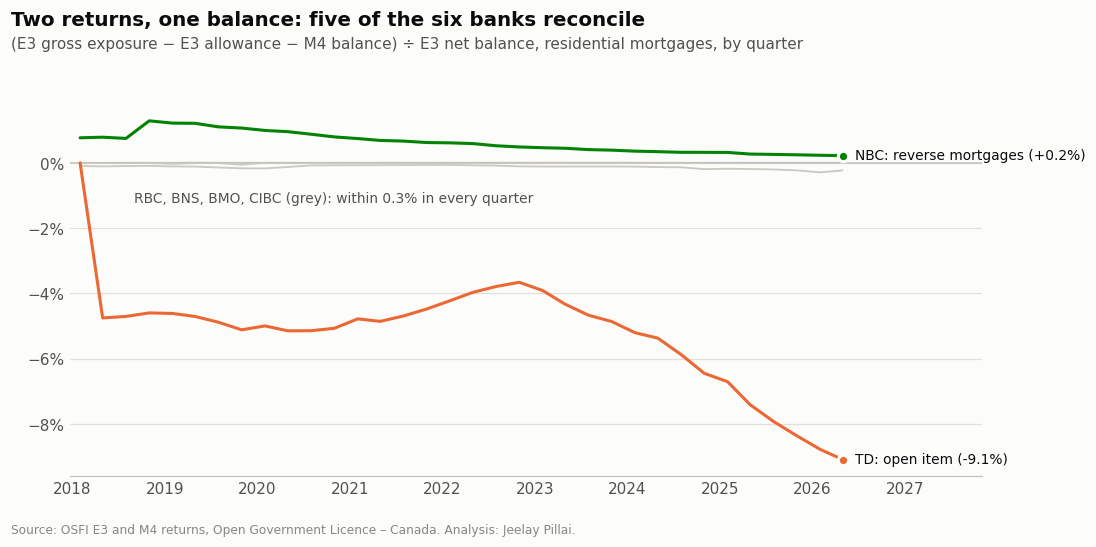

short_name
BMO                                    {'Reconciles': 34}
BNS           {'Reconciles': 32, 'Small gap (< 0.5%)': 2}
CIBC                                   {'Reconciles': 34}
NBC     {'Reconciles once reverse mortgages are added'...
RBC                            {'Small gap (< 0.5%)': 34}
TD            {'Open item (> 0.5%)': 33, 'Reconciles': 1}
Name: status, dtype: object

In [11]:
fig = ch.reconciliation_gaps(recon, SOURCE)
ch.save(fig, "fig01_reconciliation")
plt.show()
recon.groupby("short_name")["status"].agg(lambda s: s.value_counts().to_dict())

- **BMO, CIBC and Scotiabank** match to the dollar, apart from two Scotiabank quarters that are off by under 0.1%. **RBC** is 0.1–0.3% apart, small and stable.
- **National Bank's** E3 includes reverse mortgages, which M4 reports on a separate line. Adding that line closes the gap exactly.
- **TD is an open item.** From fiscal Q2 2018, TD's M4 balance is 4–9% above its E3 net balance, and the gap widens from 2023. E3 only covers loans that carry an expected-credit-loss allowance, so the likely cause is mortgages TD measures at fair value or holds for sale. TD's own filings would be needed to confirm this. All ratios in this project use E3 for both numerator and denominator, so they are consistent within each return.

#### 2.6.8 Do acquisitions distort the trend?

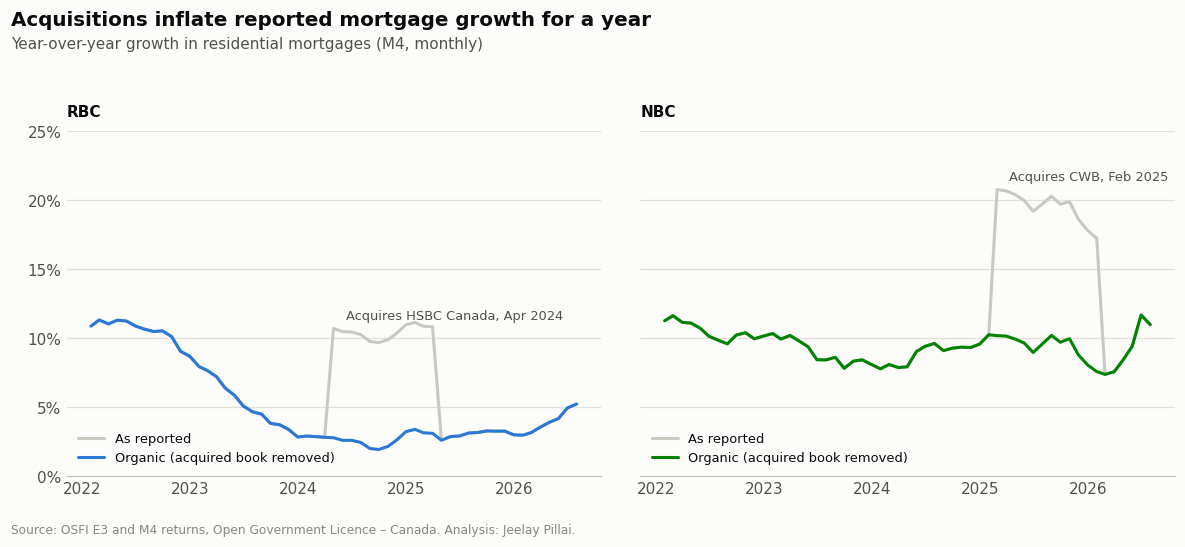

,short_name,month_end_date,mom_change_cad_mn,acquired_in_yoy_window_cad_mn
202,RBC,2024-04-30,"34,366.099","33,500.336"
672,NBC,2025-02-28,"9,930.071","9,399.654"


In [12]:
fig = ch.acquisition_growth(monthly, SOURCE)
ch.save(fig, "fig02_acquisitions")
plt.show()
monthly.loc[monthly["is_acquisition_month"],
            ["short_name", "month_end_date", "mom_change_cad_mn", "acquired_in_yoy_window_cad_mn"]]

RBC's purchase of HSBC Bank Canada (closed March 28, 2024) and National Bank's purchase of Canadian Western Bank (closed February 3, 2025) each add a whole mortgage book in a single month. Each jump is about the size of the target's last reported book. For the following 12 months, reported year-over-year growth overstates real growth. The mart therefore carries an organic growth rate, and the allowance decomposition in section 4.2 separates acquired from organic book growth.

#### 2.6.9 Does adding banks together double count anything?

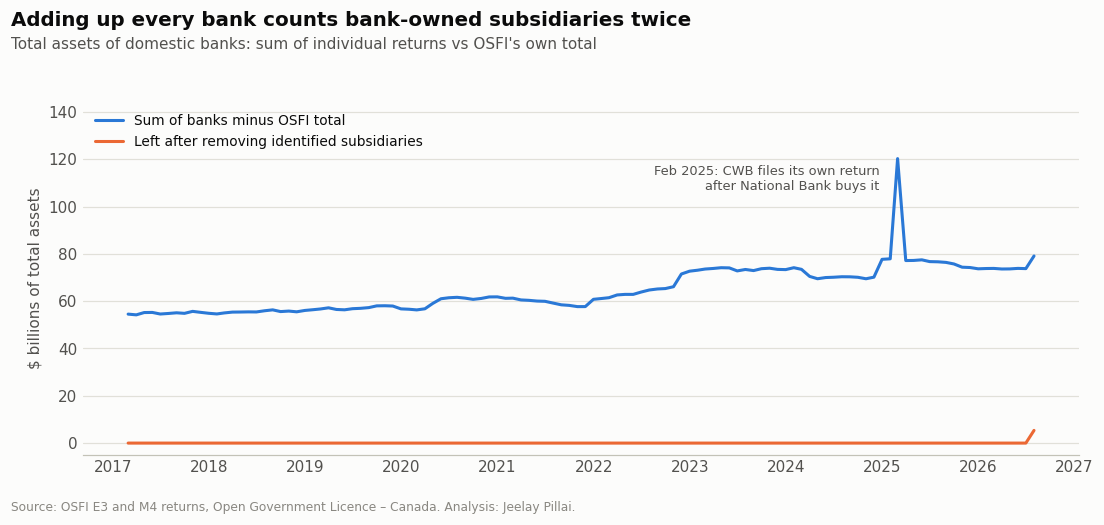

,overstatement_cad_mn,unexplained_cad_mn,overstatement_pct
min,"54,214.020",0.000,0.007
max,"120,275.111","5,361.012",0.013


In [13]:
fig = ch.double_count_chart(double_count, SOURCE)
ch.save(fig, "fig03_double_count")
plt.show()
double_count[["overstatement_cad_mn", "unexplained_cad_mn", "overstatement_pct"]].describe().loc[["min", "max"]]

OSFI's "Total Domestic Banks" leaves out banks owned by another bank, because their numbers are already inside the parent's consolidated return. Adding up every domestic bank therefore overstates the domestic total, by 0.7–1.3% of assets. With five subsidiaries identified from the data alone (Tangerine, B2B Bank, Concentra from November 2022, Home Bank from December 2024, and ADS Canadian Bank until October 2022), plus Canadian Western Bank in February 2025, the gap closes to zero in every month but one (July 2026, $5.4 billion). OSFI's List of Bank Subsidiaries would resolve that month. This project compares banks one at a time and never adds institutions together.

#### 2.6.10 Data-quality log

In [14]:
status_order = {"Open": 0, "Warning": 1, "Handled": 2, "Pass": 3}
(dq[["check_id", "area", "check_name", "status", "metric"]]
   .sort_values(["status", "check_id"], key=lambda s: s.map(status_order) if s.name == "status" else s)
   .style.hide(axis="index"))

check_id,area,check_name,status,metric
DQ08-TD,Reconciliation,E3 vs M4 residential mortgages: TD,Open,gap -9.09% to 0.00% of E3 net
DQ08-RBC,Reconciliation,E3 vs M4 residential mortgages: RBC,Warning,gap -0.29% to -0.06% of E3 net
DQ09,Consistency,Uninsured exposure never exceeds total exposure,Warning,4 violations in 713 bank-quarter-stages
DQ10,Validity,Negative Stage 3 allowances,Warning,"24 bank-quarters (NBC, fiscal 2018 to 2023)"
DQ13,Comparability,Summing banks double-counts bank-owned subsidiaries,Warning,overstatement 0.71% to 1.30% of total domestic assets; 1 month(s) not fully explained
DQ14,Comparability,Large one-quarter Stage 2 swings,Warning,21 bank-quarters where Stage 2 exposure moved more than 40% in one quarter
DQ16,Comparability,"Returns are consolidated, including foreign mortgages",Warning,"foreign-currency share of residential mortgages: BMO 17%, TD 15%, BNS 15%, NBC 10%, RBC 8%, CIBC 2%"
DQ17,Validity,CWB fiscal 2018 residential mortgages implausibly small,Warning,4 quarters where E3 is under 1% of M4
DQ02,Timeliness,Newest M4 month only partly filed,Handled,Aug 2026: 4 banks vs 52 normally
DQ03,Uniqueness,Duplicate E3 rows with conflicting values,Handled,88 rows (44 line items)


The full log, with the finding and action for each check, is in `docs/data_quality_log.md`. Of 22 checks: 5 Pass, 9 Handled, 7 Warning, 1 Open.

## 3. pAce: Analyze stage

- Perform EDA (analyze relationships between variables)

### Reflect on these questions as you complete the Analyze stage

- **What did you observe about the relationships between variables?** Impaired (Stage 3) shares fell through the pandemic, when payment deferrals held arrears down. They bottomed in 2022 (TD in 2023) and have risen at every bank since. Coverage moves with the stage mix: for the Big Six combined, a dollar of Stage 3 loans carries about 362 times the allowance of a dollar of Stage 1 loans. Uninsured mortgages carry nearly all of the allowance.
- **What do you observe about the distributions in the data?** Stage 3 shares are small, from 0.13% to 1.39% across banks and quarters, and National Bank's is the highest in every quarter. Stage 2 is volatile and step-like, reflecting model changes. Coverage differs several-fold between banks, partly because of their foreign mortgage books.
- **What transformations did you make with your data? Why?** Amounts were converted from thousands to millions. Stage exposures were turned into shares of each book and allowances into coverage, so banks of different size can be compared. Insured exposure was derived as total minus uninsured, only where the uninsured split was actually reported. Fiscal quarters were mapped to calendar quarter-ends.
- **What are some purposes of EDA before constructing a model?** To find breaks that would bias a trend model (the 2018 format change, acquisitions, misfiled quarters), to choose a measure that is comparable across banks (Stage 3 rather than Stage 2), and to pick a break point from events rather than from the data.
- **Resources:** OSFI reporting instructions (above); [Bank of Canada key interest rate](https://www.bankofcanada.ca/core-functions/monetary-policy/key-interest-rate/) for the timing of the rate cycle.
- **Ethical considerations:** Differences in reported coverage partly reflect modelling choices and foreign operations, so charts show each bank against its own history first and only then against peers.

### 3.1 The book: bigger, and less of it insured

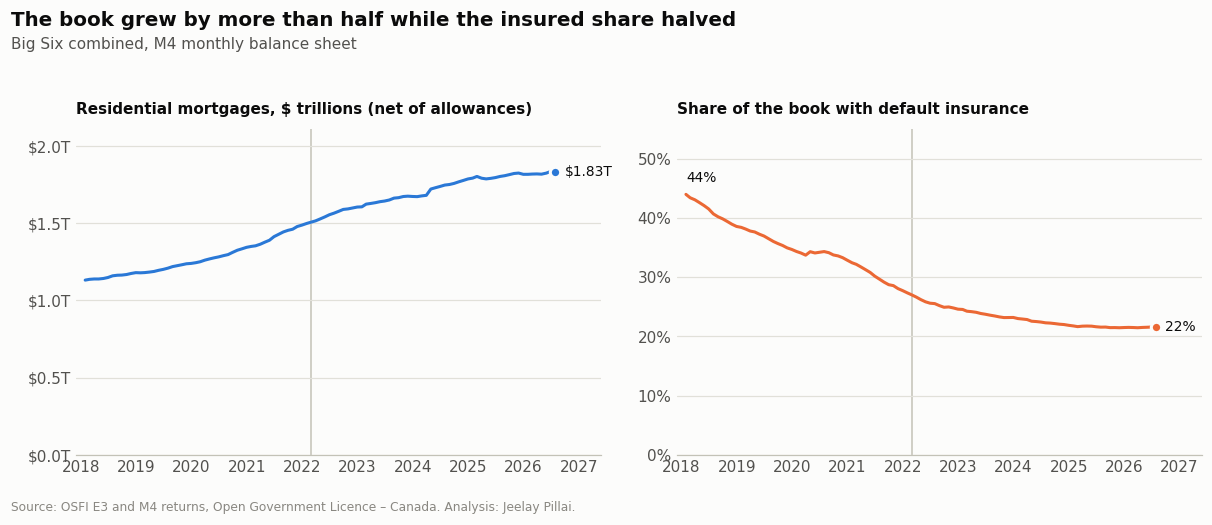

In [15]:
fig = ch.book_and_insured_share(monthly, SOURCE)
ch.save(fig, "fig04_book_insured_share")
plt.show()

Big Six residential mortgages grew 62% between January 2018 and July 2026. Meanwhile the share carrying default insurance fell from 44% to 22%. More of the credit risk now sits with the banks themselves, which matters because, as section 3.4 shows, nearly all mortgage allowances are held against uninsured loans.

### 3.2 Impaired (Stage 3) mortgages

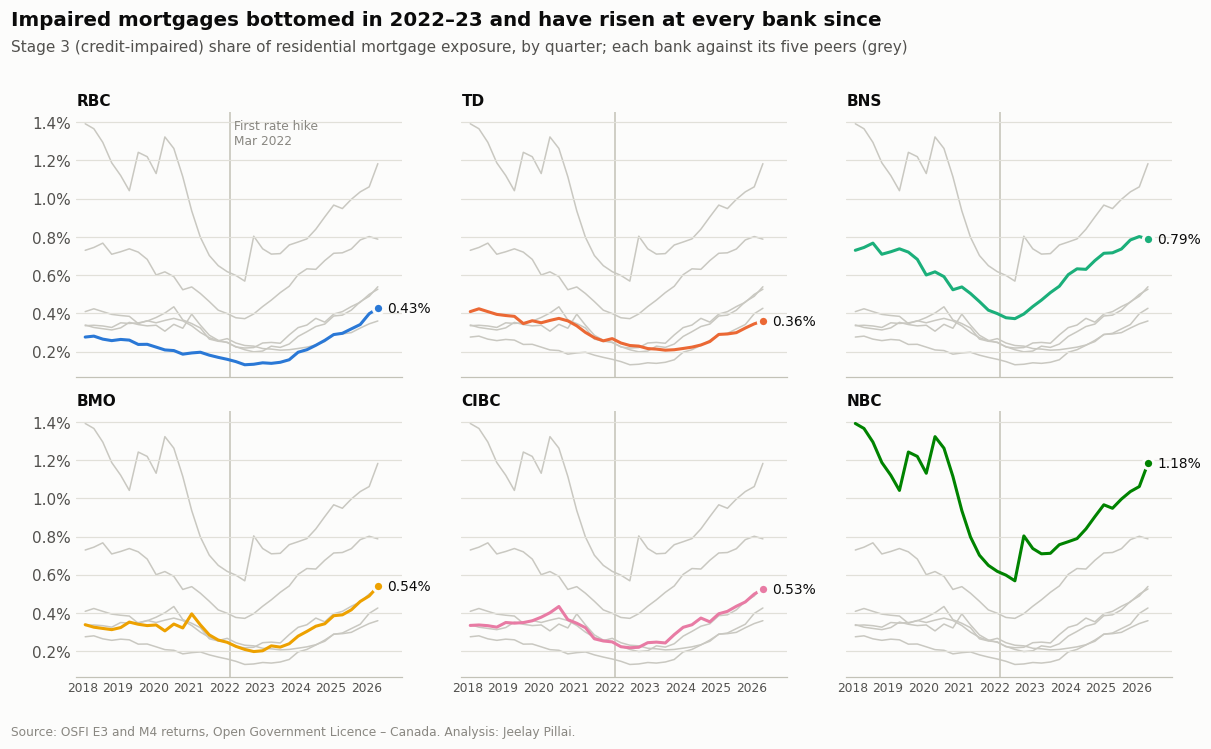

In [16]:
fig = ch.bank_small_multiples(
    quarterly, "stage3_share",
    "Impaired mortgages bottomed in 2022–23 and have risen at every bank since",
    "Stage 3 (credit-impaired) share of residential mortgage exposure, by quarter; each bank against its five peers (grey)",
    value_fmt=lambda v: f"{v:.2%}", source=SOURCE)
for ax in fig.axes:
    ch.pct_axis(ax, 1)
ch.save(fig, "fig05_stage3_by_bank")
plt.show()

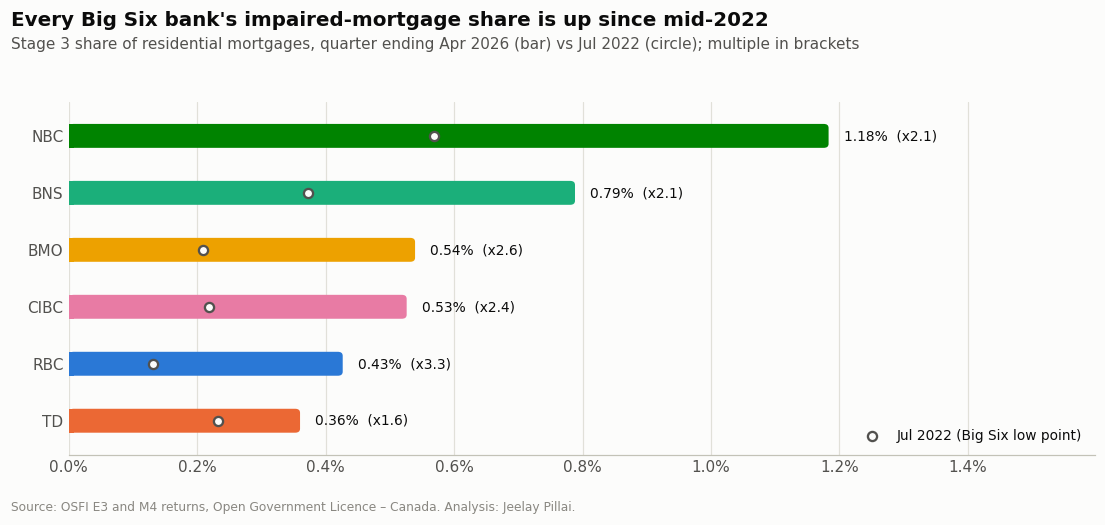

In [17]:
fig = ch.latest_stage3_bars(quarterly, SOURCE)
ch.save(fig, "fig06_stage3_latest")
plt.show()

- For the Big Six combined, the impaired share fell from 0.47% in January 2018 to a low of 0.25% in July 2022. It has since risen to 0.57% (2.3 times the low). In dollars, impaired mortgages went from $3.9 billion to $10.1 billion.
- Every bank is higher than in July 2022. The largest increases are at RBC (×3.3), BMO (×2.6) and CIBC (×2.4).
- NBC has the highest impaired share (1.18%), followed by BNS (0.79%). Both have sizeable mortgage books outside Canada (section 3.5).

### 3.3 Stage 2: a noisy early-warning signal

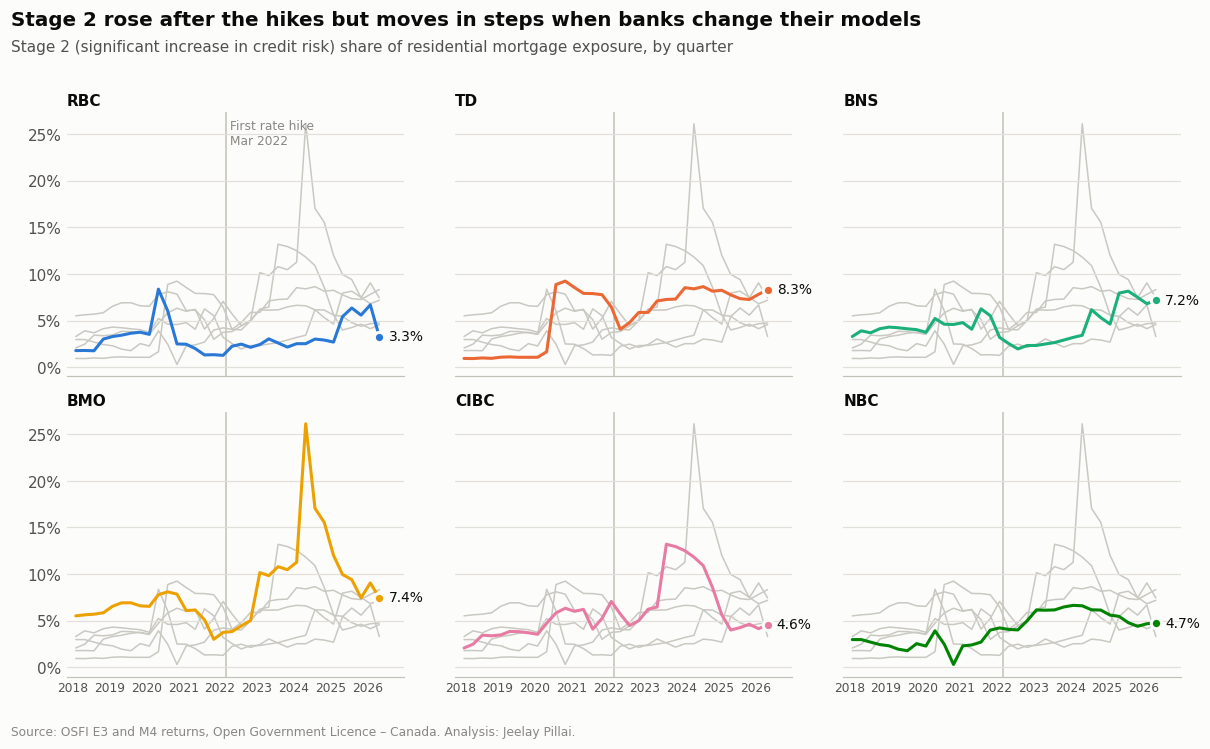

In [18]:
fig = ch.bank_small_multiples(
    quarterly, "stage2_share",
    "Stage 2 rose after the hikes but moves in steps when banks change their models",
    "Stage 2 (significant increase in credit risk) share of residential mortgage exposure, by quarter",
    value_fmt=lambda v: f"{v:.1%}", source=SOURCE)
for ax in fig.axes:
    ch.pct_axis(ax, 0)
ch.save(fig, "fig07_stage2_by_bank")
plt.show()

For the Big Six combined, the Stage 2 share was 2.4% in January 2018 and jumped in 2020, when banks' models priced in pandemic unemployment forecasts. It fell back to 4.1% by January 2022, peaked at 8.1% in April 2024 and stood at 5.8% in April 2026. The single-quarter steps, such as BMO's in 2024 and RBC's in 2025 and 2026, show why Stage 2 is better read within a bank over time than across banks.

### 3.4 Allowances and coverage

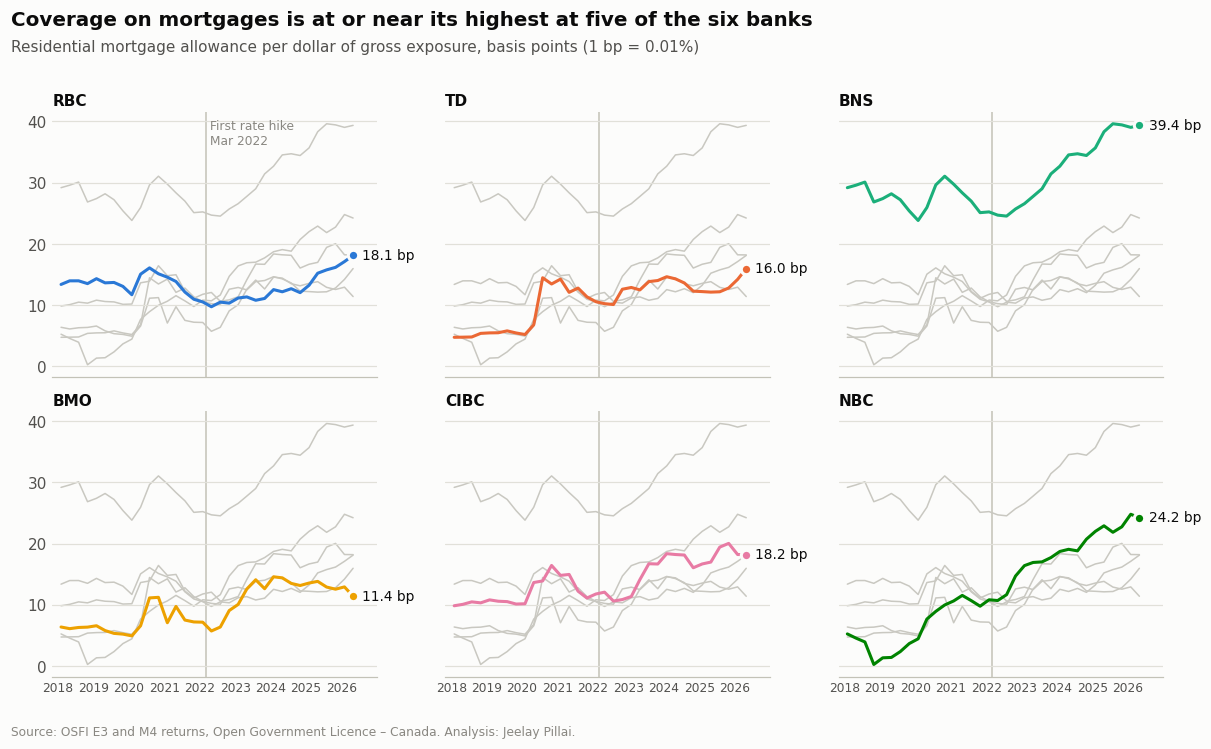

In [19]:
fig = ch.bank_small_multiples(
    quarterly, "coverage_bps",
    "Coverage on mortgages is at or near its highest at five of the six banks",
    "Residential mortgage allowance per dollar of gross exposure, basis points (1 bp = 0.01%)",
    value_fmt=lambda v: f"{v:.1f} bp", source=SOURCE)
ch.save(fig, "fig08_coverage_by_bank")
plt.show()

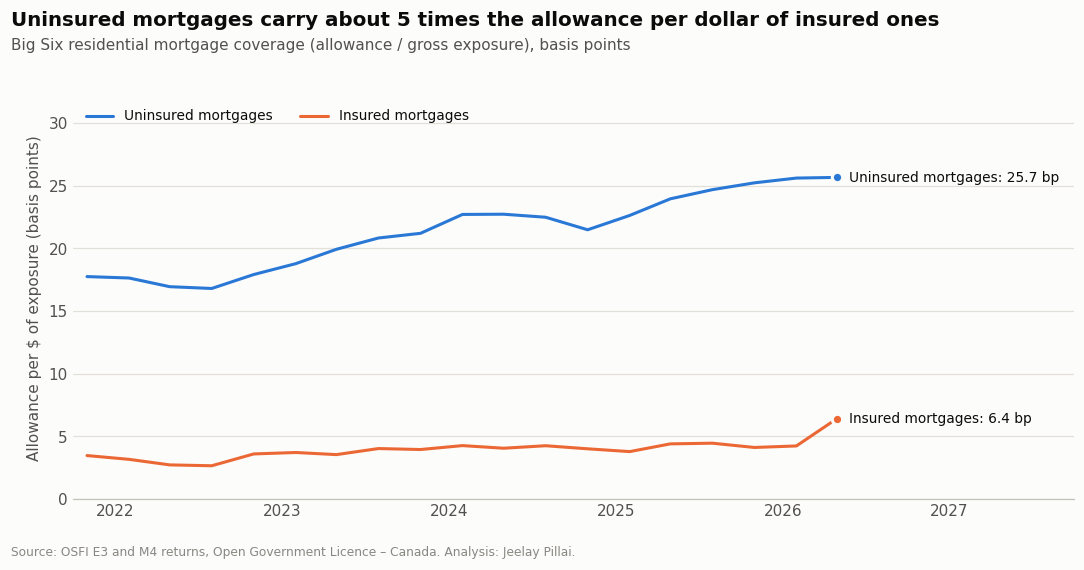

In [20]:
fig = ch.insured_vs_uninsured(
    quarterly, SOURCE,
    title="Uninsured mortgages carry about 5 times the allowance per dollar of insured ones")
ch.save(fig, "fig09_insured_vs_uninsured")
plt.show()

- Big Six mortgage allowances rose from $2.04 billion in January 2022 to $3.90 billion in April 2026 (+91%). Coverage went from 13.7 bp to 21.8 bp, the highest since IFRS 9 began.
- Uninsured mortgages are 80% of the book but 94% of the allowance. Since the split was first reported, uninsured coverage has been a median of 5.4 times insured coverage. In the latest quarter the ratio narrows because RBC's insured allowance jumped at the same time as its Stage 2 exposure halved, which looks like a change in RBC's staging method.

### 3.5 Peer snapshot: what explains the differences?

In [21]:
latest = quarterly["quarter_end_date"].max()
fx_share = (monthly[monthly["month_end_date"] == monthly["month_end_date"].max()]
            .set_index("short_name")[["foreign_currency_share", "insured_share"]])
snapshot = (quarterly[(quarterly["quarter_end_date"] == latest) & (quarterly["bank_id"] != 0)]
            .set_index("short_name")[["gross_total_cad_mn", "stage2_share", "stage3_share",
                                      "coverage_bps", "coverage_s3_pct", "uninsured_share"]]
            .join(fx_share)
            .loc[an.BANK_ORDER])
snapshot.style.format({"gross_total_cad_mn": "{:,.0f}", "stage2_share": "{:.2%}", "stage3_share": "{:.2%}",
                       "coverage_bps": "{:.1f}", "coverage_s3_pct": "{:.1f}%", "uninsured_share": "{:.0%}",
                       "foreign_currency_share": "{:.0%}", "insured_share": "{:.0%}"})

,gross_total_cad_mn,stage2_share,stage3_share,coverage_bps,coverage_s3_pct,uninsured_share,foreign_currency_share,insured_share
short_name,,,,,,,,
RBC,"499,727",3.29%,0.43%,18.1,18.0%,82%,8%,18%
TD,"321,068",8.33%,0.36%,16.0,8.8%,79%,15%,28%
BNS,"368,495",7.18%,0.79%,39.4,28.9%,80%,15%,20%
BMO,"193,817",7.45%,0.54%,11.4,2.1%,79%,17%,20%
CIBC,"289,048",4.57%,0.53%,18.2,16.9%,85%,2%,15%
NBC,"117,667",4.75%,1.18%,24.2,8.8%,58%,10%,43%


Differences between banks are only partly differences in risk:

- **Foreign books.** E3 and M4 are consolidated, so each bank's figures include mortgages booked abroad: in the US for BMO and TD, in Latin America and the Caribbean for Scotiabank, and through ABA Bank in Cambodia for National Bank. E3 has no geographic split. Scotiabank's coverage, the highest of the six, is consistent with its international book, but the data cannot separate the two.
- **Insurance mix.** National Bank has the largest insured share (over 40% of its book), which lowers the allowance it needs per dollar even though its impaired share is the highest.
- **Stage 3 coverage.** Coverage of impaired loans ranges from about 2% at BMO to about 29% at Scotiabank. Loss given default depends on loan-to-value, insurance and local housing markets, none of which are in the return.

This is why the trend models in section 4 use each bank's change over time, with bank fixed effects, rather than its level.

### 3.6 Context: mortgages vs other retail lending

In [22]:
ctx = (stages[(stages["quarter_end_date"] == latest) & (stages["insurance_status"] == "All")]
       .groupby(["product", "stage"])[["gross_exposure_cad_mn", "ecl_cad_mn"]].sum()
       .unstack("stage"))
g, e = ctx["gross_exposure_cad_mn"], ctx["ecl_cad_mn"]
pd.DataFrame({"gross_exposure_cad_bn": g.sum(axis=1) / 1e3,
              "stage2_share": g[2] / g.sum(axis=1),
              "stage3_share": g[3] / g.sum(axis=1),
              "coverage": e.sum(axis=1) / g.sum(axis=1)}).style.format(
    {"gross_exposure_cad_bn": "{:,.0f}", "stage2_share": "{:.1%}", "stage3_share": "{:.2%}", "coverage": "{:.2%}"})

,gross_exposure_cad_bn,stage2_share,stage3_share,coverage
product,,,,
Credit cards,122,16.2%,0.45%,5.42%
Non-residential mortgages,168,12.1%,1.00%,0.98%
Personal loans (incl. cards),814,11.7%,0.56%,1.87%
Residential mortgages,"1,790",5.8%,0.57%,0.22%


Residential mortgages are the largest retail book by far, but they carry the lowest coverage: 0.22%, against 5.4% for credit cards. They are secured by property, and often insured. Even a small change in mortgage coverage therefore moves billions of dollars of allowance.

### 3.7 Insights

- Mortgage credit quality has worsened steadily since mid-2022. The impaired share has more than doubled, is now above its 2018 level, and is higher than its low point at every bank.
- Allowances have nearly doubled. The rise is concentrated in uninsured loans, and the uninsured share of the book keeps growing.
- Stage 2 is too model-dependent to compare across banks; Stage 3 is the steadier signal.
- Cross-bank differences in level reflect foreign books and insurance mix as much as risk, so the models below focus on changes over time.

## 4. paCe: Construct stage

- Determine which models are most appropriate
- Construct the models
- Confirm model assumptions
- Evaluate the results

### Reflect on these questions as you complete the Construct stage

- **Do you notice anything odd?** The fitted level shift at the break is negative while the trend turns positive. That is expected: a segmented model measures the jump against the pre-hike trend projected forward, and that trend was falling. Robustness checks with later break points show the jump is not consistent, so the result is read as a change in *trend*, not a one-off step.
- **Which independent variables did you choose and why?** Time, a post-hike indicator and time since the hike, plus a separate intercept for each bank. The break point is fixed in advance by an event (the Bank of Canada's first hike on March 2, 2022), not chosen to fit the data.
- **Are each of the assumptions met?** Linearity within each segment is reasonable (see the chart). Residuals are autocorrelated and, in the panel, unequal in variance and non-normal. The models therefore use Driscoll–Kraay (panel) and Newey–West (combined series) standard errors, which remain valid under autocorrelation, unequal variance and shocks common to all banks. Variance inflation factors are below 10.
- **How well does your model fit the data?** R² is above 0.9 for both models, but the trend terms and the bank effects explain most of that. The question is not fit but whether the slope changed. It did, by a large and significant margin in every specification.
- **Can you improve it?** Possible improvements are adding drivers (unemployment, house prices, mortgage rates), using more frequent arrears data, and modelling the uninsured book alone.
- **Resources:** [statsmodels robust covariance options](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.get_robustcov_results.html).
- **Ethical considerations:** The model describes timing; it does not prove that rate increases caused the rise. Unemployment, house prices and the end of pandemic support moved over the same period.

### 4.1 Model A: did the trend in impaired mortgages change after rates rose?

An interrupted time series (segmented regression) on the Stage 3 share, in basis points:

$$\text{Stage3}_{b,t} = \alpha_b + \beta_1 t + \beta_2\,\text{post}_t + \beta_3\,(t - t^*)\,\text{post}_t + \varepsilon_{b,t}$$

- $t$ counts quarters from January 2018.
- $t^*$ is the first quarter-end after the March 2, 2022 hike (April 2022).
- $\beta_1$ is the pre-hike trend, $\beta_1 + \beta_3$ is the post-hike trend, and $\beta_2$ is any step at the break.
- The model is fitted twice: on the six banks with bank fixed effects ($\alpha_b$), and on the Big Six combined series.

In [23]:
its = an.fit_interrupted_time_series(quarterly)
summary = an.its_summary(its, "Main")
summary.set_index("model").T

model,"Six banks, bank fixed effects",Big Six combined
specification,Main,Main
break_quarter,2022-04-30,2022-04-30
n_obs,204,34
pre_trend_bps_per_qtr,-1.474,-1.174
pre_trend_p,0.000,0.000
post_trend_bps_per_qtr,2.140,2.022
post_trend_se,0.151,0.158
trend_change_bps_per_qtr,3.614,3.195
trend_change_p,0.000,0.000
level_jump_bps,-9.454,-8.667


In [24]:
# Assumption checks
pd.concat([an.its_diagnostics(its["panel"]).assign(model="Six banks"),
           an.its_diagnostics(its["aggregate"]).assign(model="Big Six combined")]
          ).set_index(["model", "check"])[["value", "reading", "response"]]

value                                            reading  \
model            check                                                                                                          
Six banks        Residual autocorrelation (Durbin-Watson)            0.358  about 2 = none; well below 2 = positive autoco...   
                 Residual autocorrelation (Ljung-Box, 4 lags), p...  0.000                          p < 0.05 = autocorrelated   
                 Unequal variance (Breusch-Pagan), p-value           0.000                         p < 0.05 = heteroskedastic   
                 Normal residuals (Jarque-Bera), p-value             0.000                              p < 0.05 = not normal   
                 Variance inflation factor: t                        8.021          > 10 = strong overlap between trend terms   
                 Variance inflation factor: post                     4.021          > 10 = strong overlap between trend terms   
                 Variance inflation factor: t_after                  4.667          > 10 = strong overlap between trend terms   
Big Six combined Residual autocorrelation (Durbin-Watson)            0.860  about 2 = none; well below 2 = positive autoco...   
                 Residual autocorrelation (Ljung-Box, 4 lags), p...  0.019                          p < 0.05 = autocorrelated   
                 Unequal variance (Breusch-Pagan), p-value           0.289                         p < 0.05 = heteroskedastic   
                 Normal residuals (Jarque-Bera), p-value             0.604                              p < 0.05 = not normal   
                 Variance inflation factor: t                        8.021          > 10 = strong overlap between trend terms   
                 Variance inflation factor: post                     4.021          > 10 = strong overlap between trend terms   
                 Variance inflation factor: t_after                  4.667          > 10 = strong overlap between trend terms   

                                                                                                              response  
model            check                                                                                                  
Six banks        Residual autocorrelation (Durbin-Watson)                         HAC / Driscoll-Kraay standard errors  
                 Residual autocorrelation (Ljung-Box, 4 lags), p...               HAC / Driscoll-Kraay standard errors  
                 Unequal variance (Breusch-Pagan), p-value                                      robust standard errors  
                 Normal residuals (Jarque-Bera), p-value             large-sample robust inference; read p-values w...  
                 Variance inflation factor: t                        expected for segmented trends; slopes are read...  
                 Variance inflation factor: post                     expected for segmented trends; slopes are read...  
                 Variance inflation factor: t_after                  expected for segmented trends; slopes are read...  
Big Six combined Residual autocorrelation (Durbin-Watson)                         HAC / Driscoll-Kraay standard errors  
                 Residual autocorrelation (Ljung-Box, 4 lags), p...               HAC / Driscoll-Kraay standard errors  
                 Unequal variance (Breusch-Pagan), p-value                                      robust standard errors  
                 Normal residuals (Jarque-Bera), p-value             large-sample robust inference; read p-values w...  
                 Variance inflation factor: t                        expected for segmented trends; slopes are read...  
                 Variance inflation factor: post                     expected for segmented trends; slopes are read...  
                 Variance inflation factor: t_after                  expected for segmented trends; slopes are read...

In [25]:
# Robustness: other break points, and the pandemic-deferral quarters removed
specs = [summary]
for q in ["2022-07-31", "2022-10-31", "2023-01-31"]:
    specs.append(an.its_summary(an.fit_interrupted_time_series(quarterly, pd.Timestamp(q)),
                                f"Break at {pd.Timestamp(q):%b %Y}"))
specs.append(an.its_summary(an.fit_interrupted_time_series(
    quarterly, exclude=(pd.Timestamp("2020-04-30"), pd.Timestamp("2021-10-31"))), "Deferral quarters removed"))
robust = pd.concat(specs, ignore_index=True)
robust[["specification", "model", "n_obs", "pre_trend_bps_per_qtr", "post_trend_bps_per_qtr",
        "trend_change_bps_per_qtr", "trend_change_p"]]

,specification,model,n_obs,pre_trend_bps_per_qtr,post_trend_bps_per_qtr,trend_change_bps_per_qtr,trend_change_p
0,Main,"Six banks, bank fixed effects",204,-1.474,2.140,3.614,0.000
1,Main,Big Six combined,34,-1.174,2.022,3.195,0.000
2,Break at Jul 2022,"Six banks, bank fixed effects",204,-1.569,2.242,3.811,0.000
3,Break at Jul 2022,Big Six combined,34,-1.244,2.139,3.382,0.000
4,Break at Oct 2022,"Six banks, bank fixed effects",204,-1.634,2.286,3.920,0.000
5,Break at Oct 2022,Big Six combined,34,-1.293,2.214,3.507,0.000
6,Break at Jan 2023,"Six banks, bank fixed effects",204,-1.598,2.414,4.012,0.000
7,Break at Jan 2023,Big Six combined,34,-1.287,2.308,3.595,0.000
8,Deferral quarters removed,"Six banks, bank fixed effects",162,-1.516,2.140,3.656,0.000
9,Deferral quarters removed,Big Six combined,27,-1.172,2.022,3.194,0.000


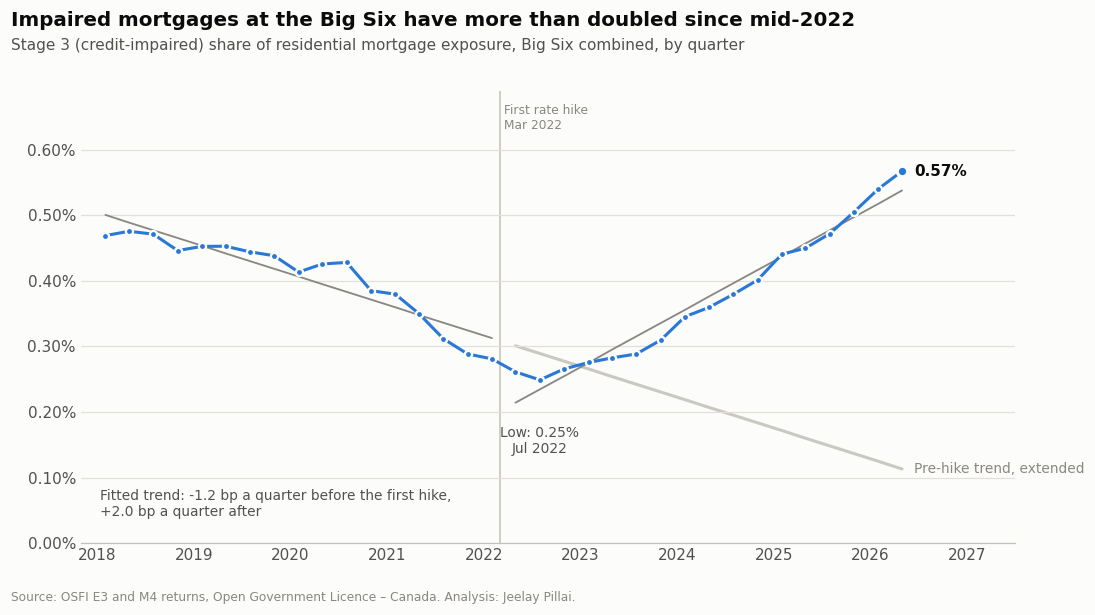

In [26]:
fitted = an.its_fitted_values(its)
fig = ch.headline_its(fitted, summary.set_index("model").loc["Big Six combined"], SOURCE)
ch.save(fig, "fig10_its_headline")
plt.show()

**Result.** Before the first hike, the combined impaired share was falling by 1.2 bp a quarter. Since then it has risen by 2.0 bp a quarter, a change in slope of +3.2 bp a quarter (p < 0.001, Newey–West). The six-bank panel with bank fixed effects gives the same picture: -1.5 bp before, +2.1 bp after (p < 0.001, Driscoll–Kraay). Moving the break to July 2022, October 2022 or January 2023, or removing the pandemic-deferral quarters, keeps the post-hike slope between 2.0 and 2.4 bp a quarter, with every slope change significant (largest p-value 9e-58). At about 8 bp a year, the impaired share is now rising about 1.7 times as fast as it was falling before the hikes.

### 4.2 Model B: what drove the rise in allowances?

The allowance on a book can be written as

$$\text{ECL} = V \times \sum_{s=1}^{3} m_s\, r_s$$

where $V$ is the gross book, $m_s$ the share of the book in stage $s$, and $r_s$ the coverage within stage $s$. Between January 2022 (just before the first hike) and the latest quarter, all three moved. A Shapley decomposition averages each factor's effect over every order in which the factors can change, so the three pieces add up exactly to the total change with no leftover term. The volume effect is further split into organic and acquired growth, using the acquired banks' last reported books.

In [27]:
decomp = an.decompose_allowance_change(quarterly, monthly)
view = decomp.set_index("short_name")[["ecl_start_cad_mn", "ecl_end_cad_mn", "ecl_change_cad_mn",
                                       "volume_organic_cad_mn", "volume_acquired_cad_mn",
                                       "stage_mix_cad_mn", "coverage_rate_cad_mn"]]
view.style.format("{:,.0f}")

,ecl_start_cad_mn,ecl_end_cad_mn,ecl_change_cad_mn,volume_organic_cad_mn,volume_acquired_cad_mn,stage_mix_cad_mn,coverage_rate_cad_mn
short_name,,,,,,,
Big Six,"2,039","3,900","1,861",462,76,"1,138",184
RBC,410,905,495,110,48,393,-56
TD,313,513,199,32,0,79,88
BNS,835,"1,450",615,124,0,685,-193
BMO,98,221,122,52,0,66,5
CIBC,302,526,223,50,0,104,70
NBC,80,285,205,55,15,20,114


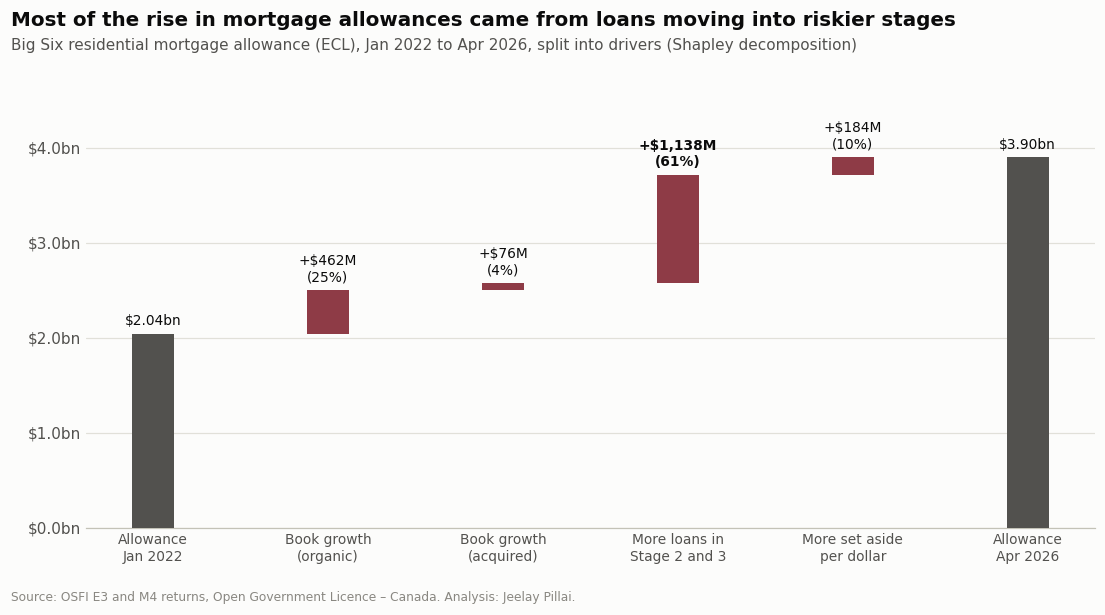

In [28]:
fig = ch.decomposition_waterfall(decomp.set_index("short_name").loc["Big Six"], SOURCE)
ch.save(fig, "fig11_decomposition")
plt.show()

**Result.** Of the $1.86 billion rise in Big Six mortgage allowances:

| Driver | Share of the rise |
|---|---|
| Loans moving into Stage 2 and Stage 3 (stage mix) | 61% |
| Organic book growth | 25% |
| Acquired books (HSBC Canada, CWB) | 4% |
| More allowance per dollar within each stage | 10% |

The rise is mostly about *where* loans sit, not how much banks hold against each stage. Bank by bank:

- **Scotiabank:** loans moved into riskier stages, but its coverage within each stage *fell*, offsetting part of the increase.
- **National Bank:** the large within-stage coverage effect partly reflects its negative Stage 3 allowance unwinding (section 2.6.6).
- **RBC:** part of the volume effect is the HSBC Canada book.

The bank-level pieces do not add up to the Big Six total, because the combined decomposition also captures shifts in weight between banks.

### 4.3 Model C: how sensitive are allowances to further migration?

Using each bank's coverage by stage in the latest quarter, the table shows the extra allowance needed if 1% of its whole book moved out of Stage 1. This is a mechanical sensitivity, not a forecast. It assumes coverage within each stage stays where it is.

In [29]:
mig = an.migration_sensitivity(quarterly)
mig.set_index("short_name")[["book_cad_mn", "ecl_cad_mn", "coverage_s1_pct", "coverage_s2_pct", "coverage_s3_pct",
                             "extra_ecl_if_to_stage2_cad_mn", "extra_ecl_if_to_stage2_pct_of_ecl",
                             "extra_ecl_if_to_stage3_cad_mn", "extra_ecl_if_to_stage3_pct_of_ecl"]].style.format({
    "book_cad_mn": "{:,.0f}", "ecl_cad_mn": "{:,.0f}", "coverage_s1_pct": "{:.3f}%", "coverage_s2_pct": "{:.2f}%",
    "coverage_s3_pct": "{:.1f}%", "extra_ecl_if_to_stage2_cad_mn": "{:,.0f}", "extra_ecl_if_to_stage2_pct_of_ecl": "{:+.0%}",
    "extra_ecl_if_to_stage3_cad_mn": "{:,.0f}", "extra_ecl_if_to_stage3_pct_of_ecl": "{:+.0%}"})

,book_cad_mn,ecl_cad_mn,coverage_s1_pct,coverage_s2_pct,coverage_s3_pct,extra_ecl_if_to_stage2_cad_mn,extra_ecl_if_to_stage2_pct_of_ecl,extra_ecl_if_to_stage3_cad_mn,extra_ecl_if_to_stage3_pct_of_ecl
short_name,,,,,,,,,
Big Six,"1,789,822","3,900",0.047%,1.34%,17.0%,232,+6%,"3,039",+78%
RBC,"499,727",905,0.044%,1.87%,18.0%,91,+10%,897,+99%
TD,"321,068",513,0.048%,1.01%,8.8%,31,+6%,280,+55%
BNS,"368,495","1,450",0.056%,1.59%,28.9%,56,+4%,"1,064",+73%
BMO,"193,817",221,0.028%,1.04%,2.1%,20,+9%,40,+18%
CIBC,"289,048",526,0.037%,1.26%,16.9%,35,+7%,489,+93%
NBC,"117,667",285,0.085%,1.21%,8.8%,13,+5%,103,+36%


For the Big Six combined, 1% of the book is $17.9 billion of mortgages:

- **Into Stage 2:** about $232 million of extra allowance (6% of today's total).
- **Into Stage 3:** about $3.0 billion (78%).

The asymmetry is the point. The cost of the renewal wave depends far more on how many loans become impaired than on how many are flagged in Stage 2.

## 5. pacE: Execute stage

- Interpret model performance and results
- Share actionable steps with stakeholders

### Reflect on these questions as you complete the Execute stage

- **What key insights emerged from your models?** The impaired share turned from falling to rising after the hikes, and the change is large, significant and robust. Most of the rise in allowances came from loans migrating to Stage 2 and 3, not from higher reserves per dollar. Allowances are far more sensitive to Stage 3 migration than to Stage 2.
- **What business recommendations do you propose?** See 5.2.
- **What potential recommendations would you make to your manager or company?** Track a peer panel built from OSFI data every quarter, using the checks in this project, and compare the bank's own Stage 3 trend and uninsured coverage against it.
- **Do you think your models could be improved? How?** Add macro drivers (unemployment, house prices, mortgage rates) and renewal timing, move to monthly arrears data, and model the uninsured book separately. The P3 income statement (provisions) and BCAR capital returns would show the earnings and capital effect.
- **What other questions could you address for the team?** Which banks' Stage 2 changes come from model updates rather than from borrowers? How do credit cards and lines of credit, which react faster, compare? What would a house-price shock do to Stage 3 coverage?
- **Resources:** listed at the end.
- **Ethical considerations:** Results are reported accounting estimates and are not a statement about any bank's safety. The project uses public aggregate data only and discloses every adjustment.

### 5.1 Summary of results

- **Impaired mortgages more than doubled from the low.** The Big Six combined Stage 3 share rose from 0.25% (July 2022) to 0.57% (April 2026), from $3.9 billion to $10.1 billion, and it is up at all six banks.
- **The trend reversed after the hikes.** Interrupted time series: -1.2 bp a quarter before the first hike, +2.0 bp a quarter after (p < 0.001; robust to break date and to removing pandemic quarters).
- **Allowances rose 91%**, from $2.04 billion to $3.90 billion, and coverage went from 13.7 bp to 21.8 bp. 61% of the rise came from loans moving into riskier stages.
- **The risk sits in uninsured loans:** 80% of the book, 94% of the allowance. The insured share of the book halved from 44% in 2018 to 22%.
- **The data needed work first.** 22 automated checks found duplicate and split rows, reused line codes, misaligned periods, two acquisitions, double-counted subsidiaries, a negative allowance and a 4–9% gap between TD's two returns. Each is fixed, worked around or disclosed.

### 5.2 Conclusion, recommendations, next steps

For a retail credit risk team benchmarking against peers:

1. **Watch Stage 3 in the uninsured book first.** It is the most comparable signal across banks, it is where the allowance sits, and moving 1% of the book into Stage 3 would cost about 13 times as much allowance as moving it into Stage 2.
2. **Benchmark changes, not levels.** Compare the bank's quarterly change in Stage 3 share and coverage with the peer median. Level gaps mostly reflect foreign books, insurance mix and model choices.
3. **Expect the trend to continue while renewals run.** About 60% of mortgages renew in 2025–2026. The post-hike trend of about 2 bp a quarter adds roughly 0.08 percentage points a year to the impaired share, about $1.4 billion of impaired loans a year on today's book.
4. **Treat Stage 2 jumps as a methodology question.** When a peer's Stage 2 doubles or halves in a quarter, as BMO's did in 2024 and RBC's did in 2025 and 2026, check its disclosures before reading it as a credit signal.
5. **Make the data checks part of the process.** Anyone combining OSFI returns should align fiscal quarters, reconcile E3 with M4, adjust for acquisitions and avoid summing subsidiaries. This pipeline does all four automatically each quarter.

**Next steps:** add OSFI's P3 (income statement) and BCAR (capital) returns to show the effect on earnings and capital, add macro drivers to Model A, and refresh the warehouse and dashboards each quarter when OSFI publishes.

### Resources

- OSFI, [Banks financial data, Open Government Portal](https://open.canada.ca/data/en/dataset/91ed76b4-a1a2-4f87-9c4c-59cd64f7a9de) and [Working with Open Government data](https://www.osfi-bsif.gc.ca/en/data-forms/open-government-osfi-financial-data/working-open-government-data)
- OSFI, [E3 instructions](https://www.osfi-bsif.gc.ca/en/data-forms/reporting-returns/filing-financial-returns/financial-reporting-instructions/allowances-expected-credit-losses-e3), [E3 change log](https://www.osfi-bsif.gc.ca/en/data-forms/reporting-returns/filing-financial-returns/financial-reporting-instructions/change-control-log-e3), [M4 instructions](https://www.osfi-bsif.gc.ca/en/data-forms/reporting-returns/filing-financial-returns/financial-reporting-instructions/balance-sheet-m4)
- Bank of Canada, [Staff Analytical Note 2025-21](https://www.bankofcanada.ca/2025/07/staff-analytical-note-2025-21/) and [key interest rate](https://www.bankofcanada.ca/core-functions/monetary-policy/key-interest-rate/)
- [RBC completes acquisition of HSBC Bank Canada](https://www.newswire.ca/news-releases/rbc-completes-acquisition-of-hsbc-bank-canada-849432219.html); [National Bank completes acquisition of Canadian Western Bank](https://www.nbc.ca/about-us/news-media/press-release/2025/20250203-nbc-concludes-acquisition-cwb.html)
- PKF, [Accounting for POCI financial assets under IFRS 9](https://www.pkf-l.com/insights/poci-financial-assets-ifrs9/)
- statsmodels, [robust covariance options](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.get_robustcov_results.html)